# Data science assessment - Delos Advisors
### Aurora Mata Sanchez
**Objective**
Build a narrow account-level AML risk model that identifies accounts likely to be suspicious based on their transaction behavior.

The model should answer the following question: **Based only on the account’s transaction activity, which accounts are most likely to be suspicious?**

This should be treated as a binary classification or risk-ranking problem.

In [2]:
#Import basic libraries
import pandas as pd
import numpy as np

In [3]:
#Load data
accounts = pd.read_csv("accounts.csv")
transactions = pd.read_csv("transactions.csv")
alerts = pd.read_csv("alerts.csv")

### General overview of data
Information (e.g. row, columns, types) of each dataset.

In [5]:
accounts.info()
accounts.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ACCOUNT_ID      10000 non-null  int64  
 1   CUSTOMER_ID     10000 non-null  object 
 2   INIT_BALANCE    10000 non-null  float64
 3   COUNTRY         10000 non-null  object 
 4   ACCOUNT_TYPE    10000 non-null  object 
 5   IS_FRAUD        10000 non-null  bool   
 6   TX_BEHAVIOR_ID  10000 non-null  int64  
dtypes: bool(1), float64(1), int64(2), object(3)
memory usage: 478.6+ KB


,ACCOUNT_ID,CUSTOMER_ID,INIT_BALANCE,COUNTRY,ACCOUNT_TYPE,IS_FRAUD,TX_BEHAVIOR_ID
0,0,C_0,184.44,US,I,False,1
1,1,C_1,175.80,US,I,False,1
2,2,C_2,142.06,US,I,False,1
3,3,C_3,125.89,US,I,False,1
4,4,C_4,151.13,US,I,False,1


In [6]:
accounts['ACCOUNT_TYPE'].describe()

count     10000
unique        1
top           I
freq      10000
Name: ACCOUNT_TYPE, dtype: object

In [7]:
transactions.info()
transactions.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1323234 entries, 0 to 1323233
Data columns (total 8 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   TX_ID                1323234 non-null  int64  
 1   SENDER_ACCOUNT_ID    1323234 non-null  int64  
 2   RECEIVER_ACCOUNT_ID  1323234 non-null  int64  
 3   TX_TYPE              1323234 non-null  object 
 4   TX_AMOUNT            1323234 non-null  float64
 5   TIMESTAMP            1323234 non-null  int64  
 6   IS_FRAUD             1323234 non-null  bool   
 7   ALERT_ID             1323234 non-null  int64  
dtypes: bool(1), float64(1), int64(5), object(1)
memory usage: 71.9+ MB


,TX_ID,SENDER_ACCOUNT_ID,RECEIVER_ACCOUNT_ID,TX_TYPE,TX_AMOUNT,TIMESTAMP,IS_FRAUD,ALERT_ID
0,1,6456,9069,TRANSFER,465.05,0,False,-1
1,2,7516,9543,TRANSFER,564.64,0,False,-1
2,3,2445,9356,TRANSFER,598.94,0,False,-1
3,4,2576,4617,TRANSFER,466.07,0,False,-1
4,5,3524,1773,TRANSFER,405.63,0,False,-1


In [8]:
transactions['TIMESTAMP'].value_counts()

TIMESTAMP
191    7161
112    7127
129    7120
52     7112
39     7066
       ... 
78     6119
3      6041
2      5552
1      5089
0      4920
Name: count, Length: 200, dtype: int64

This time variable called my attentions because it is an int type but time is ditributed between 0-191, could be hours. So the difference in time between transactions could be calculated.

In [10]:
alerts.info()
alerts.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1719 entries, 0 to 1718
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ALERT_ID             1719 non-null   int64  
 1   ALERT_TYPE           1719 non-null   object 
 2   IS_FRAUD             1719 non-null   bool   
 3   TX_ID                1719 non-null   int64  
 4   SENDER_ACCOUNT_ID    1719 non-null   int64  
 5   RECEIVER_ACCOUNT_ID  1719 non-null   int64  
 6   TX_TYPE              1719 non-null   object 
 7   TX_AMOUNT            1719 non-null   float64
 8   TIMESTAMP            1719 non-null   int64  
dtypes: bool(1), float64(1), int64(5), object(2)
memory usage: 109.2+ KB


,ALERT_ID,ALERT_TYPE,IS_FRAUD,TX_ID,SENDER_ACCOUNT_ID,RECEIVER_ACCOUNT_ID,TX_TYPE,TX_AMOUNT,TIMESTAMP
0,193,fan_in,True,82,6976,9739,TRANSFER,4.85,0
1,377,cycle,True,949,5776,2570,TRANSFER,10.27,0
2,189,fan_in,True,6280,9999,9530,TRANSFER,2.74,1
3,377,cycle,True,7999,1089,7352,TRANSFER,10.27,1
4,130,fan_in,True,12975,7025,9708,TRANSFER,3.53,2


In [11]:
#This information is also in the dataset.info
print(accounts.shape)
print(transactions.shape)
print(alerts.shape)

(10000, 7)
(1323234, 8)
(1719, 9)


Check for missing values in each dataset. This is also present in dataset.info()

In [13]:
accounts.isna().sum()

ACCOUNT_ID        0
CUSTOMER_ID       0
INIT_BALANCE      0
COUNTRY           0
ACCOUNT_TYPE      0
IS_FRAUD          0
TX_BEHAVIOR_ID    0
dtype: int64

In [14]:
transactions.isna().sum()

TX_ID                  0
SENDER_ACCOUNT_ID      0
RECEIVER_ACCOUNT_ID    0
TX_TYPE                0
TX_AMOUNT              0
TIMESTAMP              0
IS_FRAUD               0
ALERT_ID               0
dtype: int64

In [15]:
alerts.isna().sum()

ALERT_ID               0
ALERT_TYPE             0
IS_FRAUD               0
TX_ID                  0
SENDER_ACCOUNT_ID      0
RECEIVER_ACCOUNT_ID    0
TX_TYPE                0
TX_AMOUNT              0
TIMESTAMP              0
dtype: int64

The account, transactions and alert datasets contained no missing values, so no preprocessing for missing data was required

Here is to find out the frequency of fraudulent activity in accounts. 

In [18]:
accounts["IS_FRAUD"].value_counts()

IS_FRAUD
False    8315
True     1685
Name: count, dtype: int64

In [19]:
accounts["IS_FRAUD"].value_counts(normalize=True) * 100

IS_FRAUD
False    83.15
True     16.85
Name: proportion, dtype: float64

## A. Data Analysis
Task: Briefly analyze the data and explain:

### 1. What each file contains

**accounts.csv**  -> Contains account-level information (account ID, customer ID, initial balance, account type, country).

**transactions.csv**  -> Contains transaction records between accounts. It includes sender and receiver account IDs, transaction amounts, timestamps, and transaction-level information. This dataset was used to engineer account-level behavioral features.

**alerts.csv**  -> Contains alerts generated by the AML simulation. It includes transactions that triggered an alert along with additional alert-related information. This dataset was explored during the analysis but was not used in the baseline model.

### 2. Number of accounts and transactions

- **Accounts:** 10,000
- **Transactions:** 1,323,234

### 3. Number and percentage of suspicious (SAR) accounts

- **Suspicious accounts:** 1,685
- **Percentage:** 16.85%

The percentage was calculated by dividing the number of suspicious accounts by the total number of accounts.

### 4. Class imbalance

The dataset is moderately imbalanced:

- **Non-fraud accounts:** 83.15%
- **Fraud accounts:** 16.85%

To account for this imbalance, `class_weight="balanced"` was used during model training.

### 5. Important limitations of the synthetic dataset

- The dataset is synthetically generated and may not fully represent real-world AML patterns.
- Customer behavior is simulated and may not capture the complexity of genuine financial activity.
- The fraud labels are generated according to simulation rules rather than real investigations.


 **The fraud label (`IS_FRAUD`) from accounts.csv, was used as the target variable. Since the objective is to identify suspicious accounts based on their transaction behavior, the account-level fraud label provides the ground truth for training a binary classification model.

## B: Feature engineering

Task: Create relevant account-level features based on your understanding of the data, the structure of the transactions, and the objective of identifying suspicious accounts

The objective is to predict whether an account is suspicious using only its transaction behavior. Therefore, transaction-level records were aggregated into account-level behavioral features.

For example, suspicious accounts may:
- Interact with many different counterparties.
- Send or receive transactions more frequently.
- Exhibit unusual average transaction amounts.

The selected features summarize different aspects of an account's activity, including transaction frequency, transaction amounts, and the diversity of counterparties. Rather than evaluating individual transactions, the model learns from the overall behavior of each account.
  
#### Transaction frequency
 
These features measure how active an account is.

|Number| Feature | Business Question |
|-|---------|-------------------|
|1| `n_sent_transactions` | How many outgoing transactions did the account perform? |
|2| `n_received_transactions` | How many incoming transactions did the account receive? |


#### Transaction Amounts

These features describe the typical amount of money transferred by the account.

|Number| Feature | Business Question |
|-|---------|-------------------|
|3| `avg_sent_amount` | What is the typical amount of money sent by the account? |
|4| `avg_received_amount` | What is the typical amount of money received by the account? |


#### Diversity

These features measure how many different accounts interact with each account.

|Number| Feature | Business Question |
|-|---------|-------------------|
|5| `unique_receivers` | How many different accounts does the account send money to? |
|6| `unique_senders` | How many different accounts send money to this account? |


I also considered:

**Temporal activity**: avg_time_between_transactions. How frequently does this account perform transactions? 

**Balance**: avg_flow. Does the account primarily receive money or send money overall? 

However, more complex features were left for future iterations if needed.

### Features

In [25]:
#1
n_sent_transactions = (transactions.groupby("SENDER_ACCOUNT_ID")["TX_ID"].count().rename("n_sent_transactions"))
n_sent_transactions

SENDER_ACCOUNT_ID
1        24
2        18
3        19
4        23
5        38
       ... 
9995    210
9996    303
9997    183
9998    348
9999    349
Name: n_sent_transactions, Length: 9999, dtype: int64

In [26]:
#2 
n_received_transactions = (transactions.groupby("RECEIVER_ACCOUNT_ID")["TX_ID"].count().rename("n_received_transactions"))
n_received_transactions

RECEIVER_ACCOUNT_ID
3         23
5         19
6         20
7         20
9          3
        ... 
9995    1679
9996    1751
9997    1850
9998    2767
9999    2699
Name: n_received_transactions, Length: 9926, dtype: int64

The behaviour could suggest increazing account_id is how many different accounts is sending. 

In [28]:
#3
avg_sent_amount = (transactions.groupby("SENDER_ACCOUNT_ID")["TX_AMOUNT"].mean().rename("avg_sent_amount"))
avg_sent_amount

SENDER_ACCOUNT_ID
1       175.800000
2       142.050000
3       125.880000
4       151.130000
5        70.240000
           ...    
9995    392.488238
9996    341.694257
9997    256.632350
9998    321.063563
9999    311.493926
Name: avg_sent_amount, Length: 9999, dtype: float64

In [29]:
#4
avg_received_amount = (transactions.groupby("RECEIVER_ACCOUNT_ID")["TX_AMOUNT"].mean().rename("avg_received_amount"))
avg_received_amount

RECEIVER_ACCOUNT_ID
3       1.363000e+01
5       8.250000e+00
6       1.911900e+02
7       1.408300e+02
9       3.159895e+06
            ...     
9995    1.679345e+05
9996    2.795036e+05
9997    1.937551e+05
9998    1.569296e+05
9999    1.544303e+05
Name: avg_received_amount, Length: 9926, dtype: float64

In [30]:
#5
unique_receivers=transactions.groupby("SENDER_ACCOUNT_ID")["RECEIVER_ACCOUNT_ID"].nunique().rename('unique_receivers')
unique_receivers

SENDER_ACCOUNT_ID
1        1
2        1
3        1
4        1
5        2
        ..
9995    12
9996    15
9997    13
9998    18
9999    25
Name: unique_receivers, Length: 9999, dtype: int64

In [31]:
#6
unique_senders = (transactions.groupby("RECEIVER_ACCOUNT_ID")["SENDER_ACCOUNT_ID"].nunique().rename("unique_senders"))
unique_senders 

RECEIVER_ACCOUNT_ID
3         1
5         1
6         1
7         1
9         1
       ... 
9995    114
9996    135
9997    140
9998    164
9999    192
Name: unique_senders, Length: 9926, dtype: int64

In [32]:
#Add the account identifier and the target variable and use join to put all the information in a dataset.
account_features = (
    accounts[["ACCOUNT_ID", "IS_FRAUD"]]
    .set_index("ACCOUNT_ID")
    .join(n_sent_transactions)
    .join(n_received_transactions)
    .join(avg_sent_amount)
    .join(avg_received_amount)
    .join(unique_receivers)
    .join(unique_senders)
)
account_features.head()

,IS_FRAUD,n_sent_transactions,n_received_transactions,avg_sent_amount,avg_received_amount,unique_receivers,unique_senders
ACCOUNT_ID,,,,,,,
0,False,NaN,NaN,NaN,NaN,NaN,NaN
1,False,24.0,NaN,175.80,NaN,1.0,NaN
2,False,18.0,NaN,142.05,NaN,1.0,NaN
3,False,19.0,23.0,125.88,13.63,1.0,1.0
4,False,23.0,NaN,151.13,NaN,1.0,NaN


In [33]:
#Fill NaN values with 0 / this can also being done individually but in this case all variables have sense in zero
account_features = account_features.fillna(0)

In [34]:
#Is there any account with no activity?
((account_features["n_sent_transactions"].fillna(0) == 0)&(account_features["n_received_transactions"].fillna(0) == 0)).sum()

1

In [35]:
#This is to double check but this information is also in file.info()
account_features.isna().sum()

IS_FRAUD                   0
n_sent_transactions        0
n_received_transactions    0
avg_sent_amount            0
avg_received_amount        0
unique_receivers           0
unique_senders             0
dtype: int64

## C. Model development

### Logistic regression

In [38]:
#Separate between target variable and features
y = account_features["IS_FRAUD"].astype(int)
X = account_features.drop(columns="IS_FRAUD")

In [39]:
#Separate data for training and resting
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y) #Stratify preserves class ratios

In [40]:
#Since all of our variables have very different values tens or hundreds I use StandardScaler
# and handle class imbalance by increasing the importance of the minority class
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42))])

Since Logistic Regression is sensitive to feature scales, I standardized the input features using a pipeline.

In [42]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [43]:
#Test and train accuracy
print("Train accuracy:", logistic_model.score(X_train, y_train))
print("Test accuracy:", logistic_model.score(X_test, y_test))

Train accuracy: 0.742375
Test accuracy: 0.748


In [44]:
#Variable to calculate the metrics of accuracy, precision, recall and F1
y_pred = logistic_model.predict(X_test)
y_pred

array([1, 0, 0, ..., 1, 0, 0])

In [45]:
#Variable to calculate ROC-AUC
y_prob = logistic_model.predict_proba(X_test)[:, 1]

0 → Not Fraud

1 → Fraud

In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [48]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.748
Precision: 0.3403441682600382
Recall: 0.5281899109792285
F1-score: 0.41395348837209306
ROC-AUC: 0.7103407912838512


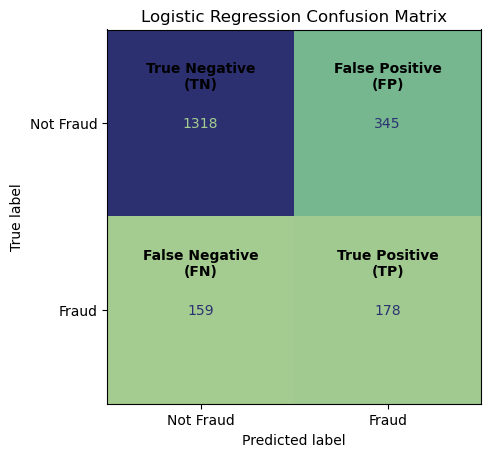

In [49]:
#Confusion matrix for Logistic Regression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Fraud", "Fraud"]
)

disp.plot(cmap="crest", colorbar=False, ax=ax)

labels = np.array([
    ["True Negative\n(TN)", "False Positive\n(FP)"],
    ["False Negative\n(FN)", "True Positive\n(TP)"]
])

for i in range(2):
    for j in range(2):
        ax.text(j,i - 0.25,labels[i, j],ha="center",va="center",fontsize=10,fontweight="bold",color="black")

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()

In [50]:
#Save logistic results
logistic_results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

### Random forest

In [52]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [53]:
print("Train accuracy:", random_forest.score(X_train, y_train))
print("Test accuracy:", random_forest.score(X_test, y_test))

Train accuracy: 1.0
Test accuracy: 0.907


In [54]:
rf_pred = random_forest.predict(X_test)
rf_prob = random_forest.predict_proba(X_test)[:, 1]

In [55]:
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1-score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))
print(classification_report(y_test, rf_pred))

Accuracy: 0.907
Precision: 0.9265536723163842
Recall: 0.486646884272997
F1-score: 0.6381322957198443
ROC-AUC: 0.9010698908518621
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      1663
           1       0.93      0.49      0.64       337

    accuracy                           0.91      2000
   macro avg       0.92      0.74      0.79      2000
weighted avg       0.91      0.91      0.89      2000



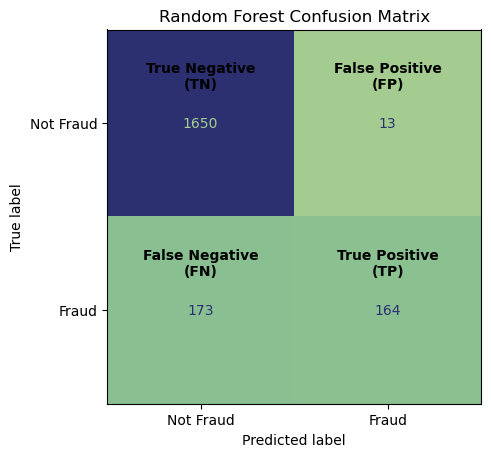

In [56]:
#Confusion matrix for random forest algorithm
cm = confusion_matrix(y_test, rf_pred)

fig, ax = plt.subplots(figsize=(5,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Fraud", "Fraud"]
)

disp.plot(cmap="crest", colorbar=False, ax=ax)

labels = np.array([
    ["True Negative\n(TN)", "False Positive\n(FP)"],
    ["False Negative\n(FN)", "True Positive\n(TP)"]
])

for i in range(2):
    for j in range(2):
        ax.text(j,i - 0.25,labels[i, j],ha="center",va="center",fontsize=10,fontweight="bold",color="black")

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()

|Not a fraud: 0 - Fraud: 1|  |
|--------------------|------|
|TN (True Negatives, Not fraud)| 1650 |
|FP (False Positives) | 13|
|FN (False Negatives) | 173|
|TP (True Positives, Fraud) | 164| 

The amount of False positives diminish to 13.

In [58]:
rf_results = {
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1-score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_prob)
}

I tried RobustScaler because it is sensitive to atypical values or outliers. This metric substract the median and divides with the interquartile range value.

In [60]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler 

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()), #For no including outliers such as big amounts of transactions or money
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', RobustScaler()),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [61]:
print("Train accuracy:", rf_pipeline.score(X_train, y_train))
print("Test accuracy:", rf_pipeline.score(X_test, y_test))

Train accuracy: 1.0
Test accuracy: 0.9055


In [62]:
rf_pred_2 = rf_pipeline.predict(X_test)
rf_prob_2 = rf_pipeline.predict_proba(X_test)[:, 1]

In [63]:
print("Accuracy:", accuracy_score(y_test, rf_pred_2))
print("Precision:", precision_score(y_test, rf_pred_2))
print("Recall:", recall_score(y_test, rf_pred_2))
print("F1-score:", f1_score(y_test, rf_pred_2))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob_2))
print(classification_report(y_test, rf_pred_2))

Accuracy: 0.9055
Precision: 0.9157303370786517
Recall: 0.4836795252225519
F1-score: 0.633009708737864
ROC-AUC: 0.8985914412300533
              precision    recall  f1-score   support

           0       0.90      0.99      0.95      1663
           1       0.92      0.48      0.63       337

    accuracy                           0.91      2000
   macro avg       0.91      0.74      0.79      2000
weighted avg       0.91      0.91      0.89      2000



Here the Random Forest is tested again with Robust_scaler, that is not like Logistic Regresion, it does not require feature scaling. This is common in tree-based algorithms and I decided to keep our first Random Forest model. 

In [65]:
feature_importance = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance": random_forest.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

feature_importance

,Feature,Importance
4,unique_receivers,0.269791
2,avg_sent_amount,0.167432
0,n_sent_transactions,0.163807
1,n_received_transactions,0.136835
5,unique_senders,0.133724
3,avg_received_amount,0.128410


The feature importance values are relatively balanced, suggesting that the model relies on multiple behavioral characteristics rather than a single dominant predictor. Among them, unique_receivers contributed the most, indicating that the diversity of outgoing counterparties was the strongest indicator of suspicious behavior in this dataset.

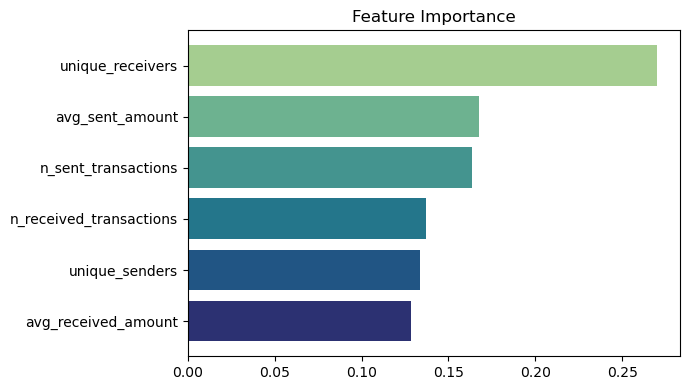

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
color_map = plt.colormaps['crest']
colors = color_map(np.linspace(0, 1, len(feature_importance["Feature"])))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    color=colors
)
plt.gca().invert_yaxis()
plt.title("Feature Importance")
plt.tight_layout()

## Model comparison: Logistic Regression and Random Forest

In [69]:
comparison = pd.DataFrame({
    "Logistic Regression": logistic_results,
    "Random Forest": rf_results
}).round(3)

comparison

,Logistic Regression,Random Forest
Accuracy,0.748,0.907
Precision,0.340,0.927
Recall,0.528,0.487
F1-score,0.414,0.638
ROC-AUC,0.710,0.901


**Logistic Regression**

* Accuracy is not the most informative metric for this problem because the dataset is imbalanced. A model could achieve high accuracy by predicting most accounts as non-fraud while failing to detect fraudulent ones.

* The Precision of 34% indicates that, among the accounts predicted as fraudulent, 34% were actually fraudulent. This relatively low Precision is expected because class_weight="balanced" encourages the model to identify more fraud cases, increasing the number of false positives.

* The Recall of approximately 53% means that the model successfully identified about half of all fraudulent accounts. In an AML context, Recall is particularly important because missing fraudulent accounts is generally more costly than investigating additional alerts.

* The ROC-AUC of 0.71 indicates that the model has a reasonable ability to distinguish between fraudulent and non-fraudulent accounts, performing substantially better than random guessing

**Random forest**

* The Random Forest achieved an Accuracy of 90.7%, although Accuracy should not be considered the primary metric because the dataset is imbalanced, as in Logistic Regression.

* The model achieved a Precision of 92.7%, meaning that most accounts predicted as suspicious were actually fraudulent.

* The Recall was approximately 49%, indicating that the model identified about half of all fraudulent accounts. Although slightly lower than Logistic Regression, the model substantially reduced the number of false positives.

* The F1-score improved to 0.64, reflecting a better balance between Precision and Recall.

* The ROC-AUC of 0.90 indicates excellent discrimination between fraudulent and non-fraudulent accounts, making Random Forest the best-performing model overall.


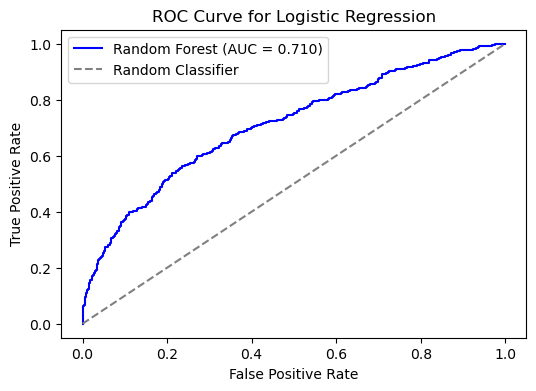

In [71]:
#ROC curve for Logistic Regression
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})",color='Blue')
plt.plot([0,1], [0,1], "--", color="gray", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Logistic Regression")
plt.legend()

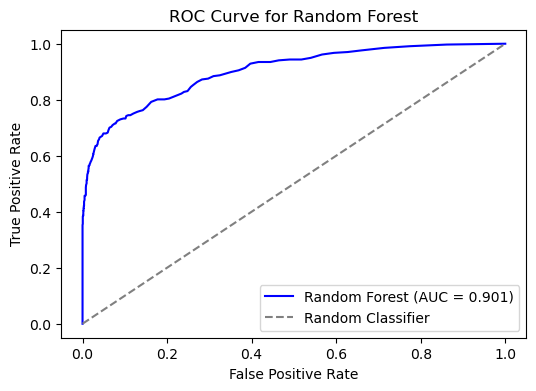

In [72]:
#ROC curve for Random Forest
fpr, tpr, _ = roc_curve(y_test, rf_prob)
auc = roc_auc_score(y_test, rf_prob)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})",color='Blue')
plt.plot([0,1], [0,1], "--", color="gray", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Random Forest")
plt.legend()

**ROC-AUC** was used as the primary metric to compare the overall discriminative ability of the models, while Precision and Recall were also analyzed to understand the trade-off between detecting fraudulent accounts and minimizing false alarms.

**In a real AML transaction monitoring system, I would prioritize Recall**. Missing a truly suspicious account (False Negative) can have significant financial and regulatory consequences, whereas investigating additional false positives is generally less costly. Therefore, maximizing the detection of suspicious accounts is often the primary objective.

Note: I considered performing hyperparameter tuning with cross-validation, but given the scope of the assessment I prioritized developing an interpretable baseline, comparing two representative models, and analyzing the resulting features.

## E. Results interpretation: Provide a short interpretation of the results

Some questions to answer include:
1. Which model performed best?
   The Random Forest model performed best overall. It achieved higher Accuracy, Precision, F1-score, and ROC-AUC than Logistic Regression, while  Logistic Regression achieved a slightly higher Recall.
   
2. What were the most important features?
    The most important features were unique_receivers and avg_sent_amount. This suggests that the diversity of outgoing counterparties and the typical amount sent were the strongest indicators used by the model to distinguish suspicious accounts.

3. What types of behavior did the model appear to identify?
    The model appeared to identify accounts with unusual transaction behavior, particularly those interacting with many different recipient accounts and exhibiting distinctive transaction patterns in terms of activity and average transaction amounts.


5. What are the main limitations of your approach?
    The model detected approximately half of the fraudulent accounts, as reflected by the Recall metric (~49%). In addition, the model was trained on a synthetic dataset with a limited number of behavioral features, which may not fully represent real-world AML scenarios.


6. What would you improve with more time?
    * Engineer additional behavioral features, such as average time between transactions, transaction velocity, and net cash flow.
    * Explore more advanced models such as XGBoost or LightGBM.
    * Perform hyperparameter tuning using cross-validation.
    * Evaluate different decision thresholds depending on the desired balance between Precision and Recall.